In [14]:
import io

import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
import aggregated_use_cases_analysis.visualization as visualization
from aggregated_use_cases_analysis.transform.hopt_simpsons import extract_latest_minima_from_hopt_df
#import aggregated_use_cases_analysis.transform.hopt as transform_hopt
from pathlib import Path
import seaborn as sns
import tqdm

sns.set_style("darkgrid")

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [4]:
path_experiments = Path("/data/horse/ws/s4610340-isml/soil_analysis/experiments")
experiments = [
    {
        "name": "003_soil_analysis_hopt_tpe_SGD_lrs",
        "dataset+model": "S2+DNN",
    },
]

for experiment in experiments:
    experiment["df"] = pd.read_csv(
        path_experiments / experiment["name"] / "data" / "processed" / "hopt" / "omniopt_results.csv",
        index_col=0
    )
    
experiments[0]["df"]

,time,RESULT,endtime,hostname,logfile_path,loss,lr_scheduler.gamma,model.dropout,model.hidden_size,optimizer.lr,optimizer.momentum,starttime,omniopt_seed,Unnamed: 1
0,2024-09-06 13:59:33,0.055665,1.725631e+09,n1055,/data/horse/ws/s4610340-isml/soil_analysis/exp...,0.055665,0.999,0.049386,8.0,0.005475,0.699281,1.725631e+09,9865,NaN
1,2024-09-06 13:59:38,0.104068,1.725631e+09,n1055,/data/horse/ws/s4610340-isml/soil_analysis/exp...,0.104068,0.990,0.226419,8.0,0.003926,0.472666,1.725631e+09,9865,NaN
2,2024-09-06 13:59:41,0.217000,1.725631e+09,n1055,/data/horse/ws/s4610340-isml/soil_analysis/exp...,0.217000,0.800,0.251550,64.0,0.002793,0.774099,1.725631e+09,9865,NaN
3,2024-09-06 13:59:46,0.085183,1.725631e+09,n1055,/data/horse/ws/s4610340-isml/soil_analysis/exp...,0.085183,0.999,0.294196,8.0,0.008116,0.371408,1.725631e+09,9865,NaN
4,2024-09-06 13:59:47,0.054712,1.725631e+09,n1055,/data/horse/ws/s4610340-isml/soil_analysis/exp...,0.054712,0.900,0.124324,32.0,0.007463,0.385546,1.725631e+09,9865,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
194,2024-09-06 14:11:22,0.526160,1.725632e+09,n1055,/data/horse/ws/s4610340-isml/soil_analysis/exp...,0.526160,0.800,0.446844,32.0,0.006974,0.366777,1.725632e+09,4943,NaN
195,2024-09-06 14:11:23,0.054655,1.725632e+09,n1055,/data/horse/ws/s4610340-isml/soil_analysis/exp...,0.054655,0.999,0.301201,32.0,0.004391,0.223489,1.725632e+09,4943,NaN
196,2024-09-06 14:11:25,0.055396,1.725632e+09,n1055,/data/horse/ws/s4610340-isml/soil_analysis/exp...,0.055396,0.999,0.219454,32.0,0.009465,0.140873,1.725632e+09,4943,NaN
197,2024-09-06 14:11:25,0.065651,1.725632e+09,n1055,/data/horse/ws/s4610340-isml/soil_analysis/exp...,0.065651,0.999,0.344784,64.0,0.006023,0.259291,1.725632e+09,4943,NaN


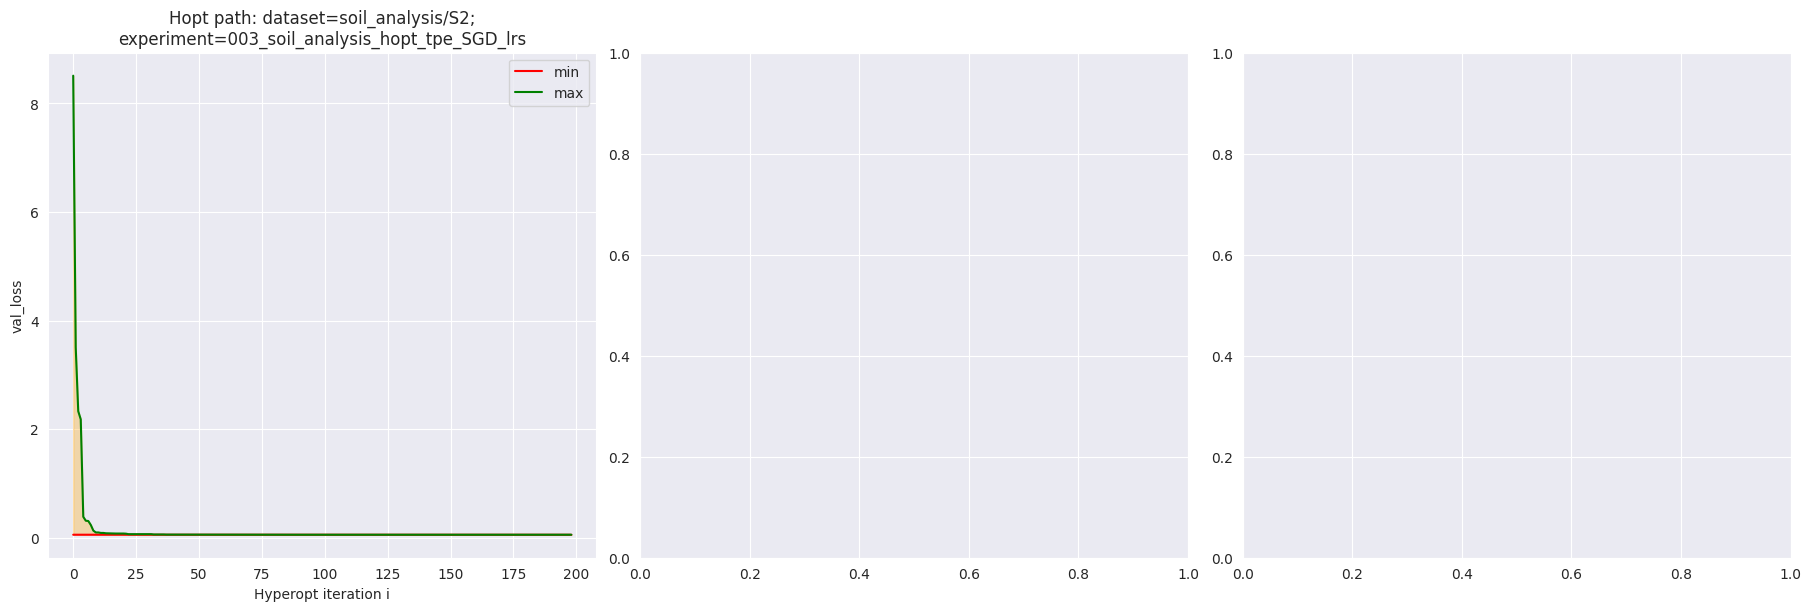

In [7]:
fig: plt.Figure

ncols = 3
nrows = len(experiments) // 3 + 1

fig, axs = plt.subplots(ncols=ncols, nrows=nrows, figsize=(ncols*6, nrows*6), constrained_layout=True)
axs = axs.flatten()

for i, experiment in enumerate(experiments):
    visualization.hopt_results_plot.plot_opt_iterations(
        df=experiment["df"],
        experiment_name=experiment["name"],
        dataset_name="soil_analysis/S2",
        hopt_algorithm_name="tpe.suggest",
        metric_name="val_loss",
        result_col="RESULT",
        title_pre="Hopt path",
        ax=axs[i]
    )


In [9]:
for experiment in experiments:
    experiment["df_minima_latest"] = extract_latest_minima_from_hopt_df(experiment["df"], result_col="RESULT")

experiment["df_minima_latest"]

,time,RESULT,endtime,hostname,logfile_path,loss,lr_scheduler.gamma,model.dropout,model.hidden_size,optimizer.lr,optimizer.momentum,starttime,omniopt_seed,Unnamed: 1
omniopt_seed,,,,,,,,,,,,,,
11,2024-09-06 13:47:05,0.054646,1.725630e+09,n1270,/data/horse/ws/s4610340-isml/soil_analysis/exp...,0.054646,0.999,0.154306,32.0,0.001278,0.207547,1.725630e+09,11,NaN
14,2024-09-06 14:30:40,0.054646,1.725633e+09,n1291,/data/horse/ws/s4610340-isml/soil_analysis/exp...,0.054646,0.990,0.248673,32.0,0.001056,0.631122,1.725633e+09,14,NaN
18,2024-09-06 13:38:09,0.054647,1.725630e+09,n1236,/data/horse/ws/s4610340-isml/soil_analysis/exp...,0.054647,0.990,0.338345,32.0,0.003874,0.895556,1.725630e+09,18,NaN
20,2024-09-06 14:28:11,0.054645,1.725633e+09,n1493,/data/horse/ws/s4610340-isml/soil_analysis/exp...,0.054645,0.990,0.278189,32.0,0.003471,0.405307,1.725633e+09,20,NaN
22,2024-09-06 14:07:03,0.053878,1.725632e+09,n1573,/data/horse/ws/s4610340-isml/soil_analysis/exp...,0.053878,0.999,0.047333,64.0,0.009856,0.899696,1.725632e+09,22,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9956,2024-09-06 14:08:04,0.054646,1.725632e+09,n1573,/data/horse/ws/s4610340-isml/soil_analysis/exp...,0.054646,0.990,0.264394,32.0,0.001391,0.600164,1.725632e+09,9956,NaN
9984,2024-09-06 14:24:06,0.054645,1.725633e+09,n1221,/data/horse/ws/s4610340-isml/soil_analysis/exp...,0.054645,0.990,0.313576,32.0,0.009268,0.724709,1.725633e+09,9984,NaN
9987,2024-09-06 14:02:33,0.054647,1.725631e+09,n1512,/data/horse/ws/s4610340-isml/soil_analysis/exp...,0.054647,0.990,0.291942,32.0,0.007385,0.316853,1.725631e+09,9987,NaN


In [15]:
import json
import numpy as np
import re


def extract_runs(results_path: Path) -> list[dict]:
    results = []
    run_paths = list(results_path.glob("*"))

    for run_result_path in tqdm.tqdm(run_paths):
        metrics_path = run_result_path / "metrics.json"
        params_path = run_result_path / "params.json"
        try:
            with params_path.open("r") as fp:
                params = json.load(fp)
            with metrics_path.open("r") as fp:
                metrics = json.load(fp)
        except Exception:
            continue
        results.append({
            "optimizer.lr": params["optimizer/lr"],
            "optimizer.momentum": params["optimizer/momentum"],
            "model.dropout": params["model/dropout"],
            "model.hidden_size": params["model/hidden_size"],
            "lr_scheduler.gamma": params["lr_scheduler/gamma"],
            #"weight_decay": pipeline_config["weight_decay"],
            "uid": params["run_uid"],
            "train_MSE": float(metrics["train_loss"][-1]["value"]),
            "val_MSE": float(metrics["val_loss"][-1]["value"]),
            "test_MSE": float(metrics["test_loss"][-1]["value"]),
            "val_RMSE": float(metrics[f"val_{params['horizon']}_RMSE/{params['target']}"][-1]["value"]),
            "test_RMSE": float(metrics[f"test_{params['horizon']}_RMSE/{params['target']}"][-1]["value"]),
        })
    return results


for experiment in experiments:
    
    print(f"Extracting runs of {experiment['name']} ...")
    experiment_results = extract_runs(path_experiments / experiment["name"] / "results")
    
    print(f"Matching runs of {experiment['name']} ...")
    seed_to_result = {}
    for omniopt_seed, run_result_row  in experiment["df_minima_latest"].iterrows():
        matching_results = [] 
        for result in experiment_results:
            if np.round(float(result["optimizer.lr"]), 6) == np.round(run_result_row["optimizer.lr"], 6) and \
               np.round(float(result["optimizer.momentum"]), 6) == np.round(run_result_row["optimizer.momentum"], 6) and \
               np.round(float(result["model.dropout"]), 6) == np.round(run_result_row["model.dropout"], 6) and \
               np.round(result["val_MSE"], 6) == np.round(run_result_row["RESULT"], 6):
                matching_results.append(result)
        assert len(matching_results) == 1
        seed_to_result[omniopt_seed] = {
            "uid": matching_results[0]["uid"],
            "train_MSE": matching_results[0]["train_MSE"],
            "val_MSE": matching_results[0]["val_MSE"],
            "test_MSE": matching_results[0]["test_MSE"],
            "val_RMSE": matching_results[0]["val_RMSE"],
            "test_RMSE": matching_results[0]["test_RMSE"]
        }
        
    experiment["seed_to_result"] = seed_to_result

Extracting runs of 003_soil_analysis_hopt_tpe_SGD_lrs ...


100%|██████████| 179200/179200 [08:36<00:00, 347.28it/s]


Matching runs of 003_soil_analysis_hopt_tpe_SGD_lrs ...


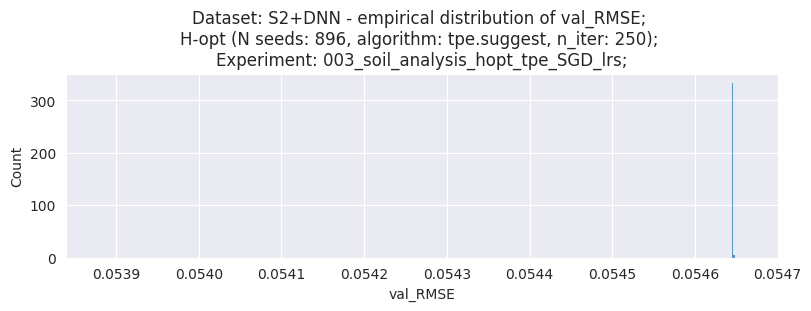

In [19]:
fig: plt.Figure

nrows = len(experiments)

fig, axs = plt.subplots(nrows=nrows, figsize=(8, nrows*3), constrained_layout=True, sharex="all")
if len(experiments)==1:
    axs = [axs]
else:
    axs = axs.flatten()

for ax, experiment in zip(axs, experiments):
    visualization.hopt_results_plot.plot_metric_hist(
        df=experiment["df_minima_latest"],
        experiment_name=experiment["name"],
        dataset_name=experiment["dataset+model"],
        hopt_algorithm_name="tpe.suggest",
        n_iter=250,
        metric_name="val_RMSE",
        result_col="RESULT",
        ax=ax
    )

<Axes: xlabel='RESULT', ylabel='Count'>

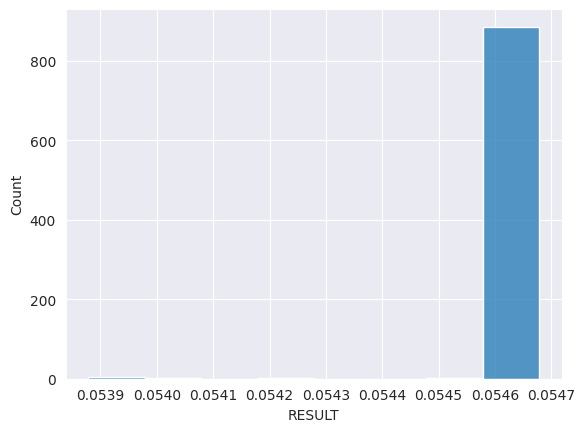

In [26]:
sns.histplot(experiments[0]["df_minima_latest"], x="RESULT", bins=10, binwidth=0.0001)

In [27]:
for experiment in experiments:
    print(f"Saving {experiment['name']} ...")
    metric_values = pd.DataFrame(
        [{"omniopt_seed": seed, **info}
         for seed, info in experiment["seed_to_result"].items()]
    )
    metric_values.to_csv(
        path_experiments / experiment["name"] / "data" / "processed" / "hopt" / "metric_values.csv",
        index=False
    )
    experiment["df_distribution"] = metric_values
    

Saving 003_soil_analysis_hopt_tpe_SGD_lrs ...


In [28]:
for experiment in experiments:
    print(experiment["name"])
    display(experiment["df_minima_latest"].loc[experiment["df_minima_latest"]["RESULT"].idxmin()])

003_soil_analysis_hopt_tpe_SGD_lrs


time                                                2024-09-06 14:07:03
RESULT                                                         0.053878
endtime                                               1725631638.954556
hostname                                                          n1573
logfile_path          /data/horse/ws/s4610340-isml/soil_analysis/exp...
loss                                                           0.053878
lr_scheduler.gamma                                                0.999
model.dropout                                                  0.047333
model.hidden_size                                                  64.0
optimizer.lr                                                   0.009856
optimizer.momentum                                             0.899696
starttime                                             1725631624.072812
omniopt_seed                                                         22
Unnamed: 1                                                      